# 02 — Latent Price and Liquidity-Adjusted Risk

This notebook uses the project’s jump-diffusion simulator to model plausible efficient prices during a halt, then calculates empirical liquidity-adjusted VaR and CVaR under liquid and stressed depth conditions.

All inputs here are **illustrative synthetic assumptions**—not market forecasts. The impact coefficient, horizon, spread, and depth must be calibrated to the instrument and venue before using these outputs for risk decisions.

In [2]:
from importlib import import_module
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

simulation_model = import_module("src.model")
JumpDiffusionParams = simulation_model.JumpDiffusionParams
LatentPriceSimulator = simulation_model.LatentPriceSimulator
LiquidityRiskEngine = simulation_model.LiquidityRiskEngine

RANDOM_SEED = 7
rng = np.random.default_rng(RANDOM_SEED)
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\kenne\OneDrive\Desktop\Friction_Modeling\Structural-Friction-Modeling


## 1. Simulate efficient prices during a halt

The observed quote can remain stale while the unobserved efficient price moves. This Monte Carlo step illustrates continuous return noise plus occasional jumps, starting from the last observed pre-halt price.

In [3]:
params = JumpDiffusionParams(
    drift=0.04,
    diffusion_vol=0.35,
    jump_intensity=250.0,
    jump_mean=-0.015,
    jump_std=0.03,
)
simulator = LatentPriceSimulator(params, seed=RANDOM_SEED)
time_seconds, latent_paths = simulator.simulate_path(
    p0=100.0,
    duration_seconds=30 * 60,
    dt=30.0,
    n_paths=1_000,
)

final_prices = latent_paths[:, -1]
print(f"Simulated paths: {latent_paths.shape[0]:,}")
print(f"Halt duration: {time_seconds[-1] / 60:.0f} minutes")
print("Final latent-price percentiles:")
print(pd.Series(final_prices).quantile([0.01, 0.05, 0.50, 0.95, 0.99]).round(2))

Simulated paths: 1,000
Halt duration: 30 minutes
Final latent-price percentiles:
0.01     95.48
0.05     98.55
0.50     99.93
0.95    101.07
0.99    101.89
dtype: float64


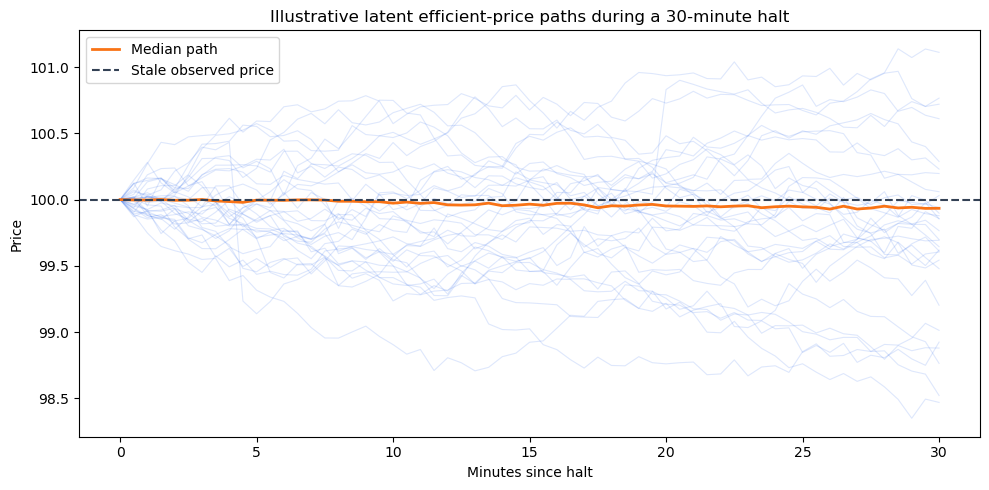

In [4]:
plt.figure(figsize=(10, 5))
for path in latent_paths[:30]:
    plt.plot(time_seconds / 60, path, color="#2563eb", alpha=0.15, linewidth=0.8)
plt.plot(
    time_seconds / 60,
    np.median(latent_paths, axis=0),
    color="#f97316",
    linewidth=2,
    label="Median path",
)
plt.axhline(100.0, color="#334155", linestyle="--", label="Stale observed price")
plt.xlabel("Minutes since halt")
plt.ylabel("Price")
plt.title("Illustrative latent efficient-price paths during a 30-minute halt")
plt.legend()
plt.tight_layout()
latent_figure_path = PROJECT_ROOT / "docs" / "images" / "latent_price_paths.png"
latent_figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(latent_figure_path, dpi=160, bbox_inches="tight")
plt.show()

## 2. Calculate liquidity-adjusted VaR and CVaR

Use the same synthetic return sample for both states so the difference isolates the assumed liquidity penalty. Here positions are shares, depth is shares available, and spread is dollars per share. The impact parameter is chosen illustratively; it is not a calibrated estimate.

In [5]:
n_scenarios = 20_000
returns = rng.normal(loc=0.0001, scale=0.012, size=n_scenarios)
position_shares = 2_500.0
portfolio_value = 250_000.0
alpha = 0.99

# Illustrative impact calibration; validate in consistent units against real data.
risk_engine = LiquidityRiskEngine(alpha=alpha, liquidity_impact_factor=0.0002)
liquid_depth = rng.lognormal(mean=np.log(30_000), sigma=0.25, size=n_scenarios)
liquid_half_spread = rng.lognormal(mean=np.log(0.01), sigma=0.20, size=n_scenarios)

halt_depth = rng.lognormal(mean=np.log(80), sigma=0.35, size=n_scenarios)
halt_half_spread = rng.lognormal(mean=np.log(0.10), sigma=0.25, size=n_scenarios)

liquid_var, liquid_cvar = risk_engine.compute_l_cvar(
    returns,
    portfolio_value,
    position_shares,
    liquid_half_spread,
    liquid_depth,
)
halt_var, halt_cvar = risk_engine.compute_l_cvar(
    returns,
    portfolio_value,
    position_shares,
    halt_half_spread,
    halt_depth,
)

risk_summary = pd.DataFrame(
    {
        "L-VaR ($)": [liquid_var, halt_var],
        "L-CVaR ($)": [liquid_cvar, halt_cvar],
    },
    index=["Liquid market", "Halt / stressed liquidity"],
)
print(risk_summary.to_string(float_format=lambda value: f"${value:,.2f}"))

                           L-VaR ($)  L-CVaR ($)
Liquid market              $6,923.38   $7,957.67
Halt / stressed liquidity  $8,023.46   $8,969.49


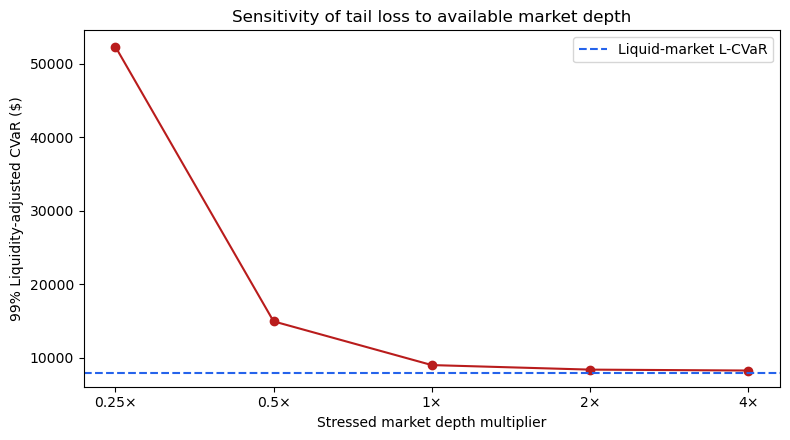

Halt-stress CVaR uplift vs liquid: $1,011.83


In [6]:
depth_multipliers = np.array([0.25, 0.5, 1.0, 2.0, 4.0])
sensitivity_cvar = []
for multiplier in depth_multipliers:
    _, cvar = risk_engine.compute_l_cvar(
        returns,
        portfolio_value,
        position_shares,
        halt_half_spread,
        halt_depth * multiplier,
    )
    sensitivity_cvar.append(cvar)

plt.figure(figsize=(8, 4.5))
plt.plot(depth_multipliers, sensitivity_cvar, marker="o", color="#b91c1c")
plt.axhline(liquid_cvar, linestyle="--", color="#2563eb", label="Liquid-market L-CVaR")
plt.xscale("log", base=2)
plt.xticks(depth_multipliers, [f"{x:g}×" for x in depth_multipliers])
plt.xlabel("Stressed market depth multiplier")
plt.ylabel("99% Liquidity-adjusted CVaR ($)")
plt.title("Sensitivity of tail loss to available market depth")
plt.legend()
plt.tight_layout()
sensitivity_figure_path = PROJECT_ROOT / "docs" / "images" / "depth_sensitivity.png"
sensitivity_figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(sensitivity_figure_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Halt-stress CVaR uplift vs liquid: ${halt_cvar - liquid_cvar:,.2f}")

## 3. Read the results carefully

The latent-price fan chart visualizes model uncertainty, not observed prices. L-VaR/L-CVaR add a modeled liquidation cost to simulated mark-to-market loss; extreme results can arise when depth is close to zero. The current engine uses a simple quadratic impact penalty and empirical percentile/mean-tail calculations, so validate units, calibration, tail sample size, and execution assumptions before production use.

For a real analysis, replace the synthetic returns, spreads, and depth with timestamp-aligned instrument-level observations; model halts explicitly; and evaluate parameter sensitivity across assets, venues, and market regimes.